# The reference engine ORE, QuantLib and what stays offline

- **Level:** 3, comparison with published methods
- **Prerequisites:** notebooks 02 and 06 of this topic
- **Reading time:** about 50 minutes

**Question:** For which books of the case does the exposure of the engine agree with the open-source reference engine ORE within Monte Carlo error, where does it stop agreeing and by how many standard errors, and what do the closed forms of QuantLib say about the Hull-White formulas underneath?

## Objectives

By the end of this notebook you can:

- say what the Open Source Risk Engine (ORE) and QuantLib offer for counterparty exposure, and what neither offers;
- read a reconciliation of an exposure profile against ORE in combined Monte Carlo standard errors, and compute it from the committed arrays;
- say for which of the six variants of case C12 the engine agrees with ORE, for which it does not, and what the document says about the causes;
- read the comparison of the engine's Hull-White closed forms with QuantLib's, and the triangle closed form, simulation and ORE;
- say what stays offline in the product, and why.

## Setup

Install the pinned environment once, in a virtual environment, with the familiar command:

```bash
pip install -r notebooks/requirements.txt
```

or only the packages this notebook uses, with the same exact pins:

```bash
pip install riskvalidation==1.1.0 numpy==2.4.6 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows) builds `.venv-notebooks` for you. The next cell imports the packages and prints their versions.

In [1]:
# Import the tools and print the versions they run with, to compare them with notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from riskvalidation.ccr import exposure as ex
from riskvalidation.ccr import hw1f
from riskvalidation.ccr import swaps as sw
from riskvalidation.validation import ccr as vc

for name in ("riskvalidation", "numpy", "matplotlib"):
    print(name, md.version(name))

riskvalidation 1.0.1
numpy 2.4.6
matplotlib 3.11.2


## Data

The data are the six variants of case C12 (counterparty credit risk): the single swap, the netting set of four swaps, the CSA with 10 and with 20 business days, the CSA with initial margin, and the wrong-way-risk variant. The trades are synthetic conventions, the curve is the US Treasury par curve of 2025-09-30 (licence class `mirror-allowed`). Each document holds the `ore_reconciliation` block: the profile that ORE 1.8.17.0 produced for the same trades and curve (10,000 antithetic samples, run natively with the Python wheel, not in this notebook), the agreement point by point, and the status.

- **Files read:** the six documents under `data/derived/C12/`, keys `outputs.exposure`, `outputs.ore_reconciliation`, `outputs.initial_margin` and `tests`. ORE is not installed and not run here: it is a 77.6 MB native wheel that stays offline, and its configuration files are kept under version control in the pipeline as evidence of what was run (`data-pipeline/pipeline/cases/c12/ore_inputs/`).
- **Truth status:** `synthetic-calibrated`. What a reconciliation shows is agreement between two implementations of the same model on the same inputs, not that the model is right (notebook 06 shows that it is not).

The next cell loads the six documents and prints the status of each reconciliation.

In [2]:
# Load the six committed variants of C12 (three folders below the repository root), print the ORE status of each
ROOT = Path("../../..").resolve()
names = ["single-swap", "netting-set", "csa-mpor-10d", "csa-mpor-20d", "with-im", "wrong-way-risk"]
docs = {n: json.loads((ROOT / "data" / "derived" / "C12" / f"{n}.json").read_text(encoding="utf-8")) for n in names}
LIGHT = {"green": "green", "red": "red", "amber": "amber"}
baked = docs["single-swap"]["provenance"]["riskvalidation_version"]
print("baked by riskvalidation", baked, "| installed", rv.__version__)
STATUS = {"reconciled": "reconciled", "not-applicable": "not applicable"}

print(f"{'variant':16s}{'status':16s}{'all within 2 se':>20s}{'ORE run, s':>18s}")
for n in names:
    o = docs[n]["outputs"]["ore_reconciliation"]
    seconds = round(o["run_seconds"], 1) if o["run_seconds"] else "-"
    status = STATUS[o["status"]]
    inside = {True: "yes", False: "no", None: "-"}[o["all_within_two_se"]]
    print(f"{n:16s}{status:16s}{inside:>20s}{seconds!s:>18}")
print("ORE version:", docs["single-swap"]["outputs"]["ore_reconciliation"]["ore_version"])
print("variant with no ORE reconciliation, and why:",
      docs["wrong-way-risk"]["outputs"]["ore_reconciliation"]["reason"]["en"])

baked by riskvalidation 1.0.1 | installed 1.0.1
variant         status               all within 2 se        ORE run, s
single-swap     reconciled                       yes              18.1
netting-set     reconciled                       yes              23.6
csa-mpor-10d    reconciled                        no              48.8
csa-mpor-20d    reconciled                        no              53.2
with-im         reconciled                        no              48.7
wrong-way-risk  not applicable                     -                 -
ORE version: 1.8.17.0
variant with no ORE reconciliation, and why: ORE's wrong-way example is a different model (a correlated credit LGM), not the Hull and White (2012) hazard on the portfolio value, so this variant has no ORE reconciliation.


## Method

### Step 1: the engine side, simulated and in closed form

The product's side of the comparison is the exposure of the single swap, computed two ways with the engine: by simulating the Hull-White short rate (notebook 01), and by the closed form that the exposure of a payer swap equals the payoff of a payer swaption on the remaining swap, priced by Jamshidian's decomposition, $EE_B(t) = \mathrm{Swaption}(0; t) / P(0, t)$ (notebook 06). The identity holds on the reset dates of the swap. The next cell rebuilds the simulation with the case's curve, calibration, seed and grid.

In [3]:
# Rebuild the simulation of the single swap with the case's curve, calibration, seed and grid
single = docs["single-swap"]["outputs"]
base = docs["netting-set"]["outputs"]
tenors = np.array([p["tenor_years"] for p in base["curve"]["points"]])
zeros = np.array([p["zero_rate"] for p in base["curve"]["points"]])
a, sigma = base["calibration_used"]["a"], base["calibration_used"]["sigma"]
p0, forward = hw1f.curve_functions(zeros, tenors)
named = base["named_parameters"]
report = np.array(named["time_grid_years"]["value"])
main = np.concatenate([[0.0], report])
swaps = [
    sw.Swap(t["trade_id"], t["notional"]["amount"], t["fixed_rate"], t["side"] == "payer",
            t["start_years"], t["maturity_years"], t["fixed_frequency_per_year"])
    for t in base["book"]["trades"]
]
merged = np.unique(np.round(np.concatenate([main] + [main + d for d in (14 / 360, 28 / 360)]), 12))
grid = sw.simulation_grid(merged, swaps)
n_paths, seed = named["path_count"]["value"], named["seed"]["value"]
r = hw1f.simulate_short_rate(grid, a, sigma, forward, n_paths, seed)
numeraire = hw1f.bank_account(grid, r, a, sigma, p0, forward)
values = sw.swap_values_on_grid(swaps, grid, r, a, sigma, p0, forward)
ix = np.searchsorted(grid, report - sw.TIME_TOL)
p0r = p0(report)
ee_d, ee_d_se = ex.expected_exposure(values[0][:, ix], numeraire[:, ix])
ee_sim, ee_sim_se = ee_d / p0r, ee_d_se / p0r
print("paths:", n_paths, "| seed:", seed, "| report dates:", report.size)
print("simulated EE, peak:", round(float(ee_sim.max()), 0), "at", float(report[ee_sim.argmax()]), "y")

paths: 20000 | seed: 42 | report dates: 33
simulated EE, peak: 294524.0 at 5.0 y


The next cell computes the closed-form EE of the swap at its reset dates and measures its distance to the simulated EE in Monte Carlo standard errors.

In [4]:
# The closed-form EE of the single swap at its reset dates, and its distance to the simulated EE
swap = swaps[0]
resets = sw.reset_times(swap)
pick = [k for k, t in enumerate(report) if np.min(np.abs(resets - t)) < 1e-9]
analytic = ex.analytic_ee_single_swap(swap, report[pick], a, sigma, p0, forward)
test1 = vc.ee_analytic_vs_simulated(analytic * p0r[pick], ee_d[pick], ee_d_se[pick], 3.0)
k_1y, k_5y = [pick.index(np.searchsorted(report, y - 1e-9)) for y in (1.0, 5.0)]
print("dates in the closed-form check:", len(pick))
print("analytic EE at 1 y and 5 y:", np.round(analytic[[k_1y, k_5y]], 0))
print("largest gap to the simulated EE, in standard errors:", round(test1.statistic, 3))

dates in the closed-form check: 19
analytic EE at 1 y and 5 y: [141685. 295711.]
largest gap to the simulated EE, in standard errors: 0.891


## Comparison

What the open-source world offers for counterparty exposure, as the persisted research of the case records it from the primary sources (the ORE methodology and release at tag 1.8.17.0, QuantLib's repository and package index, the Basel framework) and as this product uses it.

- **ORE (Open Source Risk Engine), 1.8.17.0.** A C++ engine under a modified BSD licence, with a Python wheel (a 77.6 MB native wheel, Windows, Linux and macOS). It simulates exposure under a Linear Gauss Markov interest-rate model, computes EE, ENE, PFE and EEPE, CVA, DVA, FVA, MVA and KVA, SA-CCR and BA-CVA, and has a dynamic initial margin by regression and an ISDA SIMM module. Its methodology describes **two ways to model the margin period of risk**: the preferred close-out approach, with an auxiliary grid offset by the MPoR from the default grid (the one Contraste follows, with the sticky-date value), and a legacy lagged approach. It is the most complete open reference for what the case computes.
- **QuantLib.** Curves, instruments, pricing engines and short-rate models, with closed-form Hull-White bond options and a Jamshidian swaption engine, which the engine's closed forms are checked against. QuantLib has **no packaged exposure or XVA workflow**: the exposure loop on top of it is written by the user.
- **The gap.** The research found no mature open-source engine for the banking-book side (asset-liability management, liquidity) to reconcile against; for counterparty exposure ORE is the reference, and the research's rule is that Contraste must not claim ORE's numbers as validated beyond the reconciliations it actually runs.
- **What stays outside.** The ISDA SIMM methodology is published under a notice that restricts its use to a participant's own transactions, so its risk weights are neither reimplemented nor published in an open product; the regression dynamic initial margin of ORE stands in for it and is labelled a proxy. The Andersen, Pykhtin and Sokol (2017) timelines of the margin period of risk are not modelled. Real counterparty credit curves are not public: the proxy is a market average.
- **What stays offline in the product.** ORE, a native engine of tens of megabytes, runs only in the data pipeline and its results are committed; the browser reads the committed documents. The simulations of this topic run in seconds, but the 309-date back-test with its simulated critical values takes minutes and is committed too.
- **Where Contraste stands relative to this.** The engine implements the Hull-White simulation, collateral, CVA and wrong-way risk in Python with tests of its own, reconciles with ORE and QuantLib where they provide a number, and states where they do not (wrong-way risk: ORE's example is a different model). Notebook 08 uses that as a claim.

The three steps below run the comparison with that reference: the engine's profile against ORE's, the numbers that matter for capital, and the closed forms against QuantLib.

### Step 2: the EE profile against ORE

ORE and the engine each give an estimate of the same expected exposure at 33 dates, with a Monte Carlo error. The engine's `reconcile_ee_profile` takes the two profiles with their errors and returns, as statistic, the largest gap in **combined standard errors**

$$z_k = \frac{|EE_k - EE^{ORE}_k|}{\sqrt{se_k^2 + se_k^{ORE\,2}}}$$

with a Contraste internal gate of 2 for green (a gate, not a regulatory threshold). Both profiles are the undiscounted forward-measure EE of the document: ORE's discounted profile divided by $P(0,t)$, the same transformation the engine's profile goes through. The next cell computes the statistic for the five variants that have a reference, from the committed arrays.

In [5]:
# The reconcile_ee_profile statistic of each variant from the EE arrays of both engines
checked = [n for n in names if docs[n]["outputs"]["ore_reconciliation"]["status"] != "not-applicable"]
k1 = 11
z = {}
print(f"{'variant':14s}{'statistic':>12s}{'points in 2 se':>20s}{'light':>8s}"
      f"{'ORE/Python 1 y':>16s}{'mean z':>10s}")
for n in checked:
    o = docs[n]["outputs"]
    ee, ee_se = np.array(o["exposure"]["ee"]["values"]), np.array(o["exposure"]["ee"]["mc_se"])
    ore = o["ore_reconciliation"]
    ref, ref_se = np.array(ore["ore_ee"]["values"]), np.array(ore["ore_ee"]["mc_se"])
    t = vc.reconcile_ee_profile(ee, ee_se, ref, ref_se, k_se=2.0)
    z[n] = (ee - ref) / np.sqrt(ee_se**2 + ref_se**2)
    inside = int(np.sum(np.abs(z[n]) <= 2))
    ratio_1y = ref[k1] / ee[k1]
    print(f"{n:14s}{t.statistic:12.3f}{inside:16d} /{ee.size:3d}{LIGHT[t.light.value]:>8s}", end="")
    print(f"{ratio_1y:16.4f}{float(z[n].mean()):10.2f}")
mta0 = [r for r in docs["csa-mpor-10d"]["tests"] if r["segment"] == "minimum-transfer-amount-0"][0]
print("diagnostic row, CSA 10 days with a zero minimum transfer amount in both engines:",
      round(mta0["statistic"], 3), LIGHT[mta0["light"]])
print("what the document says of the minimum transfer amount:",
      docs["csa-mpor-10d"]["outputs"]["collateral"]["limit"]["en"])

variant          statistic      points in 2 se   light  ORE/Python 1 y    mean z
single-swap          0.775              33 / 33   green          1.0040     -0.17
netting-set          0.715              33 / 33   green          1.0042     -0.18
csa-mpor-10d         9.931              17 / 33     red          0.9868      2.38
csa-mpor-20d         7.086              21 / 33     red          0.9988      1.47
with-im             11.739              32 / 33     red          0.8936      0.19
diagnostic row, CSA 10 days with a zero minimum transfer amount in both engines: 3.637 red
what the document says of the minimum transfer amount: The Andersen, Pykhtin and Sokol timelines are not modelled. The minimum transfer amount acts on the balance of the report grid; ORE margins on its own call schedule, so its effect is larger there (see the ORE rows).


The next cell draws the standardised difference between the engine and ORE along the dates for the single swap, the 10-day CSA and the CSA with initial margin, against the band of two standard errors.

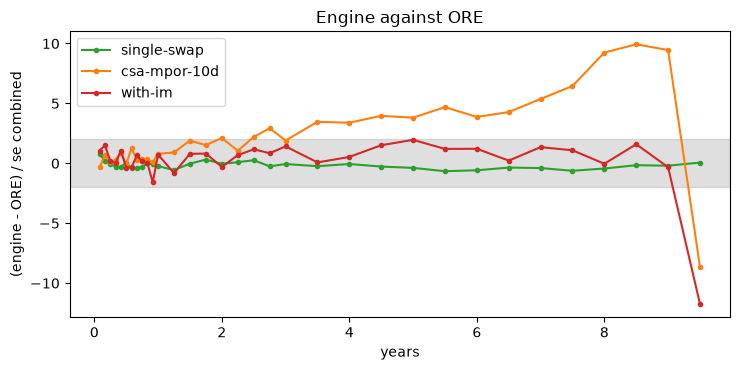

In [6]:
# Draw (engine - ORE) / combined se along the dates for three variants, against the band of two standard errors
fig, ax = plt.subplots(figsize=(7.5, 3.8))
for n, color in (("single-swap", "tab:green"), ("csa-mpor-10d", "tab:orange"), ("with-im", "tab:red")):
    dates = np.array(docs[n]["outputs"]["exposure"]["time_grid_years"])
    ax.plot(dates, z[n], "o-", ms=3, color=color, label=n)
ax.axhspan(-2, 2, color="grey", alpha=0.25)
ax.set_xlabel("years")
ax.set_ylabel("(engine - ORE) / se combined")
ax.set_title("Engine against ORE")
ax.legend()
fig.tight_layout()
plt.show()

The green line, the single swap, stays inside the grey band at all 33 dates and wanders around zero, which is what two estimates of the same quantity should do. The orange line, the CSA, leaves the band at many dates and does so on one side, so the engine and ORE disagree systematically and not by noise. The red line, the CSA with initial margin, is inside the band except at a few dates where it spikes above ten. The figure measures the disagreement and does not decide who is right, since ORE is not an oracle either; the document leaves both gaps as findings.

### Step 3: the EEPE, the CVA and the dynamic initial margin

The same comparison applies to the numbers that matter for capital. The document records, for each variant, the EEPE and the CVA of both engines with their combined error (`eepe_agreement`, `cva_agreement`), and for the initial-margin variant the profile of the mean dynamic initial margin of ORE's `dim_cube` against the engine's. The next cell prints the difference of each in combined standard errors, with the committed light,, the ratio of the two mean DIM and the statistic of the engine's reconciliation applied to the DIM profile.

In [7]:
# EEPE and CVA of the engine and of ORE in combined standard errors; then the mean DIM of both
print(f"{'variant':14s}{'EEPE Py':>10s}{'EEPE ORE':>10s}{'z':>8s}{'light':>8s}", end="")
print(f"{'CVA Py':>10s}{'CVA ORE':>10s}{'z':>8s}{'light':>8s}")
tests = ("ccr.ore_eepe_agreement", "ccr.ore_cva_agreement")
zs = {}
for n in checked:
    o = docs[n]["outputs"]["ore_reconciliation"]
    e, c = o["eepe_agreement"], o["cva_agreement"]
    lights = {row["test_id"]: row["light"] for row in docs[n]["tests"] if row["test_id"] in tests}
    zs[n] = (e["difference"] / e["combined_se"], c["difference"] / c["combined_se"])
    print(f"{n:14s}{e['python']:10.1f}{e['ore']:10.1f}{zs[n][0]:8.2f}{LIGHT[lights[tests[0]]]:>8s}"
          f"{c['python']:10.2f}{c['ore']:10.2f}{zs[n][1]:8.2f}{LIGHT[lights[tests[1]]]:>8s}")

im = docs["with-im"]["outputs"]
ore_im, py_im = im["ore_reconciliation"], im["initial_margin"]
dim_py, dim_py_se = np.array(py_im["dim"]["values"]), np.array(py_im["dim"]["mc_se"])
dim_ore, dim_ore_se = np.array(ore_im["ore_dim"]["values"]), np.array(ore_im["ore_dim"]["mc_se"])
t_dim = vc.reconcile_ee_profile(dim_py, dim_py_se, dim_ore, dim_ore_se, k_se=2.0)
ratio = dim_ore / dim_py
print("mean DIM at 1 y, engine and ORE:", round(dim_py[k1], 0), round(dim_ore[k1], 0))
print("ORE / engine DIM ratio: mean, smallest, largest:",
      round(float(ratio.mean()), 3), round(float(ratio.min()), 3), round(float(ratio.max()), 3))
print("largest DIM gap in combined standard errors:", round(t_dim.statistic, 1), LIGHT[t_dim.light.value])

variant          EEPE Py  EEPE ORE       z   light    CVA Py   CVA ORE       z   light
single-swap      87550.9   87810.5    0.30   green  10337.65  10371.78    0.37   green
netting-set      59954.1   60157.2    0.31   green   9477.77   9510.70    0.40   green
csa-mpor-10d     22777.8   22527.8   -1.55   green    699.53    653.89  -15.89     red
csa-mpor-20d     33183.5   32665.3   -2.20     red   1011.72    973.14   -9.88     red
with-im            212.9     198.0   -0.71   green      7.02      6.69   -1.40   green
mean DIM at 1 y, engine and ORE: 110493.0 104805.0
ORE / engine DIM ratio: mean, smallest, largest: 0.884 0.692 0.997
largest DIM gap in combined standard errors: 137.4 red


The next cell draws the difference between the engine and ORE for the EEPE and for the CVA of each variant, in combined standard errors.

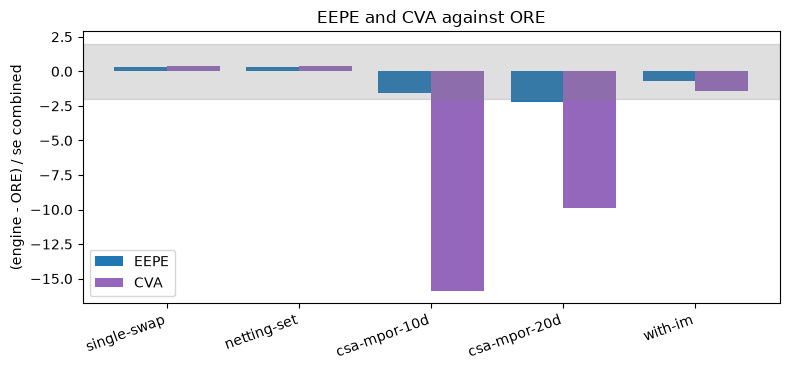

In [8]:
# Draw the EEPE and CVA differences between the engine and ORE of each variant in combined standard errors
x = np.arange(len(checked))
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.bar(x - 0.2, [zs[n][0] for n in checked], width=0.4, color="tab:blue", label="EEPE")
ax.bar(x + 0.2, [zs[n][1] for n in checked], width=0.4, color="tab:purple", label="CVA")
ax.axhspan(-2, 2, color="grey", alpha=0.25)
ax.set_xticks(x, checked, rotation=20, ha="right")
ax.set_ylabel("(ORE - engine) / se combined".replace("ORE - engine", "engine - ORE"))
ax.set_title("EEPE and CVA against ORE")
ax.legend()
fig.tight_layout()
plt.show()

The first two variants sit inside the band for both numbers. For the CSAs the EEPE is borderline (inside for the 10-day agreement, just outside for 20 days) but the CVA is far outside, at about ten to sixteen standard errors, with ORE giving the lower CVA. The CVA is the number most sensitive to the early part of the profile, where the minimum transfer amount acts, which is why the CVA exposes a disagreement that the EEPE nearly hides. With initial margin the two numbers are small and both inside. The bars compare two engines, not an engine and the truth.

### Step 4: the closed forms against QuantLib, and the triangle

The engine's Hull-White bond option and Jamshidian swaption are compared with QuantLib 1.44 (`HullWhite.discountBondOption` and `JamshidianSwaptionEngine`) at bake time, in four rows whose gate is a relative difference of $10^{-6}$; QuantLib is not installed here, so we read the rows the document committed, with both values. Then we close the triangle for the single swap: the analytic EE (which needs no simulation), the engine's simulated EE and ORE's, at the reset dates. If the three agree within their errors, three independent routes (a closed form, a simulation in Python and a simulation in a C++ engine) give the same exposure.

In [9]:
# The four QuantLib rows, then the closed form, the simulation and ORE on the single swap at the reset dates
for row in docs["single-swap"]["tests"]:
    if row["test_id"].startswith("ccr.quantlib"):
        x = row["extras"]
        rel = abs(x["engine"] - x["quantlib"]) / abs(x["quantlib"])
        print(f"{row['test_id']:30s} engine {x['engine']:12.6f} | QuantLib {x['quantlib']:12.6f}"
              f" | relative difference {rel:.1e} | {LIGHT[row['light']]}")

ore = single["ore_reconciliation"]
ore_ee, ore_se = np.array(ore["ore_ee"]["values"])[pick], np.array(ore["ore_ee"]["mc_se"])[pick]
sim, sim_se = ee_sim[pick], ee_sim_se[pick]
print("dates in the triangle:", len(pick))
no_se = np.zeros(len(pick))
sim_vs_closed = vc.reconcile_ee_profile(sim, sim_se, analytic, no_se, k_se=2.0)
ore_vs_closed = vc.reconcile_ee_profile(ore_ee, ore_se, analytic, no_se, k_se=2.0)
ore_vs_sim = vc.reconcile_ee_profile(ore_ee, ore_se, sim, sim_se, k_se=2.0)
print("largest simulation - closed form, in standard errors:", round(sim_vs_closed.statistic, 3))
print("largest ORE - closed form, in standard errors:", round(ore_vs_closed.statistic, 3))
print("largest ORE - simulation, in combined standard errors:", round(ore_vs_sim.statistic, 3))

ccr.quantlib_bond_call         engine     0.039287 | QuantLib     0.039287 | relative difference 0.0e+00 | green
ccr.quantlib_bond_put          engine     0.035838 | QuantLib     0.035838 | relative difference 0.0e+00 | green
ccr.quantlib_swaption_payer    engine  7010.256951 | QuantLib  7010.256285 | relative difference 9.5e-08 | green
ccr.quantlib_swaption_receiver engine 11140.502980 | QuantLib 11140.503857 | relative difference 7.9e-08 | green
dates in the triangle: 19
largest simulation - closed form, in standard errors: 0.891
largest ORE - closed form, in standard errors: 0.465
largest ORE - simulation, in combined standard errors: 0.659


The next cell draws the EE of the single swap by the three routes at the reset dates.

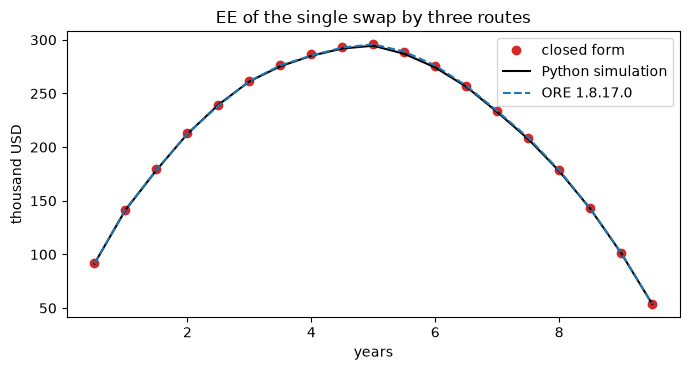

In [10]:
# Draw the EE of the single swap by the closed form, the Python simulation and ORE
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(report[pick], analytic / 1e3, "o", color="tab:red", label="closed form")
ax.plot(report[pick], sim / 1e3, "-", color="black", label="Python simulation")
ax.plot(report[pick], ore_ee / 1e3, "--", color="tab:blue", label="ORE 1.8.17.0")
ax.set_xlabel("years")
ax.set_ylabel("thousand USD")
ax.set_title("EE of the single swap by three routes")
ax.legend()
fig.tight_layout()
plt.show()

The three curves cannot be told apart by eye, and the numbers above put the largest distance between any two of them below one combined standard error. A closed form, a Python simulation and a C++ simulation, written independently, give the same exposure for a swap with no collateral, so the Hull-White formulas of the engine are implemented consistently. The QuantLib rows say the same of the closed forms in isolation. What the picture cannot show is any book with collateral, where the routes diverge, nor whether the Hull-White model itself describes the market.

## Results

**Answer:** The engine agrees with ORE on the books without collateral and not on the margined ones. For the single swap and the four-swap netting set the largest gap of the EE profile is 0.775 and 0.715 combined standard errors, inside the gate of 2 at all 33 dates; for the CSA of 10 days it is 9.931, for the CSA of 20 days 7.086 and with initial margin 11.739, and ORE's mean dynamic initial margin is on average 0.884 of the engine's. On the single swap the closed form, the simulation and ORE agree within 0.891 standard errors, and the engine's swaptions agree with QuantLib to a relative 9.5e-8.

- **The simple books agree with ORE.** The EEPE differs by 0.30 and 0.31 standard errors (87,551 against 87,811 USD, and 59,954 against 60,157 USD), and the CVA by 0.37 and 0.40 (10,338 against 10,372 USD, and 9,478 against 9,511 USD).
- **The collateralised books do not.** For the CSA of 10 days the EE profile agrees at only 17 of 33 dates, the EEPE is within the gate (-1.55) but the CVA is not: ORE gives 653.89 USD against the engine's 699.53, a gap of 15.9 combined standard errors. For 20 days the profile agrees at 21 of 33 dates, and both the EEPE (-2.20) and the CVA (-9.88) are red. The document's reading is that the minimum transfer amount acts on the balance of the report grid in the engine while ORE margins on its own call schedule, so its effect is larger in ORE.
- **Initial margin.** With initial margin the profile after margin agrees at 32 of 33 dates, and the EEPE and CVA are green (-0.71 and -1.40), but the mean dynamic initial margin does not: ORE's is on average 0.884 of the engine's, 104,805 against 110,493 USD at one year. The document marks the cause UNVERIFIED and notes that the expected exposure after margin agrees, so the two estimates of the margin differ where the exposure after margin hides it.
- **Wrong-way risk has no reference.** ORE's wrong-way example is another model (a credit factor correlated with the rate), so the variant carries `not-applicable` and its check is the paper's Appendix (notebooks 03 and 08).
- **QuantLib.** The bond call and put agree with QuantLib 1.44 to the last digit and the payer and receiver swaptions to 9.5e-8 and 7.9e-8 in relative terms, far inside the gate of 1e-6.

What this notebook does not show: it does not run ORE or QuantLib (they stay offline and the document commits what they gave), and it does not say which engine is right where they differ; the document leaves the CSA and DIM gaps as findings.

## Summary

- ORE is the most complete open reference for counterparty exposure; QuantLib gives the Hull-White closed forms but no exposure workflow; both stay offline, and the product commits what they produced.
- The reconciliation is a statistic in combined Monte Carlo standard errors with a gate of 2: the single swap and the netting set pass (largest gap 0.78), the CSA variants and the dynamic initial margin do not (largest gaps 9.9, 7.1 and 137).
- The closed form, the Python simulation and ORE agree within a standard error on the single swap, so the model is implemented consistently; where collateral enters, the engines differ and the document reports it.
- A reconciliation compares two implementations of the same model; it is silent on whether the model fits the market (notebook 06).

**What to try next.** Compute the same statistics with only the first 16 dates and see how the number of points moves the maximum; look in `data-pipeline/pipeline/cases/c12/ore_inputs/` at the configuration files that produced the ORE profile. Then continue with notebook 08.

## References

- Open Source Risk Engine (ORE), release 1.8.17.0. https://github.com/OpenSourceRisk/Engine
- Open Source Risk Engine, Methodology, value adjustments and margin period of risk (xva.tex at tag 1.8.17.0). https://github.com/OpenSourceRisk/Engine/blob/1.8.17.0/Docs/UserGuide/methods/xva.tex
- QuantLib, the open-source quantitative finance library. https://github.com/lballabio/QuantLib
- Andersen, L., Pykhtin, M. and Sokol, A. (2017), Rethinking the margin period of risk, Journal of Credit Risk 13(1). https://doi.org/10.21314/JCR.2016.218
- Hull, J. and White, A. (1990), Pricing interest-rate-derivative securities, Review of Financial Studies 3(4), 573-592. https://doi.org/10.1093/rfs/3.4.573
- BCBS, Basel Framework, CRE53 Internal model method for counterparty credit risk (in force 2023-01-01, published 2020-06-05). https://www.bis.org/basel_framework/chapter/CRE/53.htm?inforce=20230101&published=20200605